# 06. Dense 기준문장 cosine 피처 (의미 기반 E/S/G 측정)

## 목적

`05b_TF_IDF.ipynb`는 seed 단어의 **TF-IDF 가중치 합산**으로 E/S/G 점수를 만든다 — "보고서에 ESG 단어가 얼마나 자주·독특하게 등장하는가"라는 **빈도(count) 기반** 측정이다. 이 방식은 (1) 보고서가 길수록(verbosity) 점수가 커지는 **규모 효과**가 섞이고, (2) seed 사전 기반 cosine은 seed 점수와 순환 관계라 수렴타당도 검증에 쓸 수 없다.

이 노트북은 **의미 기반(dense)** 대안 측정을 만든다.

- E/S/G **기준문장(paraphrase, 차원당 3개)** 을 한국어 문장 임베딩 `nlpai-lab/KURE-v1`(bge-m3 한국어 retrieval 파인튜닝, 1024-dim, ctx 8192)으로 인코딩한다.
- 사업보고서 **핵심 3개 섹션(II 사업의 내용 · IV 경영진단 MD&A · VI 이사회 등)** 의 문장들과 **cosine 유사도**를 계산하고, 문장 축 **top-k 평균 → 패러프레이즈 평균**으로 차원별 점수(`cosine_E/S/G`)를 만든다.
- cosine은 길이 정규화된 방향 유사도이므로 "회사 규모·업종으로 인한 보고서 분량 차이"의 영향을 1차로 줄인다. 우리가 보려는 것은 *"ESG를 많이 언급한 기업이 등급이 높은가"* 가 아니라, **사업보고서의 ESG 서술 자체가 외부 ESG 평가와 어떤 관련이 있는가** 이다.

### 실행 환경
이 노트북은 **로컬(Apple Silicon MPS)** 과 **Google Colab(GPU + Google Drive 마운트)** 양쪽에서 돌아간다. 프로젝트 전체를 Google Drive에 올린 뒤 Colab에서 열면, 아래 **0번 셀의 `DRIVE_PROJECT_ROOT` 한 줄만** 본인 Drive 경로로 맞추면 된다.

### 분석 흐름
0. 환경 셋업 → 1. import/경로 → 2. 파라미터 → 3. 코퍼스 로드 → **4. 섹션 추출 → 5. 경량 클리닝 → 6. 문장 분할(← 전처리, 점검·수정 가능)** → 7. 기준문장 → 8. 모델 로드 → 9. 임베딩 → 10. cosine 집계 → 11. 피처 → 12. 등급 merge → 13. Spearman 3×3 → 14. heatmap → 15. 집계 변형 비교 → 16. TF-IDF 수렴타당도 → 17. 그룹차 검정 → 18. 회귀 패널 → 19. 회귀(OLS·Binary·Ordered, 두 스펙) → 20. 저장 → 21. 정리

> **주의(cheap-talk)**: 사업보고서 표현이 실제 ESG 성과를 그대로 반영하지는 않는다. 381행은 수업용 pilot 표본이며 결과는 인과가 아닌 **연관**으로 읽는다.


## 0. 실행 환경 셋업 (로컬 / Google Colab 공용)

- **Colab**: 아래 `DRIVE_PROJECT_ROOT`를 Drive에 올린 프로젝트 폴더 경로로 수정 → 셀 실행 시 패키지 설치·한글 폰트 설치·Drive 마운트가 자동으로 진행된다. **런타임 → 런타임 유형 변경 → GPU(T4)** 를 권장한다(임베딩이 CPU보다 수십 배 빠름).
- **로컬**: 아무것도 수정하지 않아도 된다. `uv add sentence-transformers seaborn pyarrow statsmodels` 가 되어 있으면 그대로 실행된다.

In [19]:
# ★ Colab에서만: Drive에 올린 프로젝트 폴더 경로로 수정하세요 ★
DRIVE_PROJECT_ROOT = '/content/drive/MyDrive/esg-dart-project'

import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
print('실행 환경:', 'Google Colab' if IN_COLAB else '로컬')

if IN_COLAB:
    # Colab에는 torch/pandas/numpy/matplotlib/scipy가 기본 설치됨 → 나머지만 설치
    get_ipython().system('pip install -q sentence-transformers kiwipiepy seaborn statsmodels pyarrow')
    # 한글 폰트(그래프 깨짐 방지)
    get_ipython().system('apt-get -qq -y install fonts-nanum')
    import matplotlib.font_manager as fm
    _nanum = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    if Path(_nanum).exists():
        fm.fontManager.addfont(_nanum)
    # Google Drive 마운트
    from google.colab import drive
    drive.mount('/content/drive')
    print('Drive 마운트 완료')


실행 환경: 로컬


## 1. import 및 경로 설정

임베딩은 GPU(Colab `cuda`) > Apple Silicon(`mps`) > `cpu` 순으로 선택한다. `PROJECT_ROOT`는 Colab이면 위에서 정한 Drive 경로, 로컬이면 현재 위치에서 자동 추론한다. 모든 입력·출력 경로가 `PROJECT_ROOT` 하나에서 파생되므로 프로젝트를 통째로 옮겨도 동작한다.

In [20]:
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams
from scipy.stats import spearmanr, mannwhitneyu, ttest_ind

try:
    import seaborn as sns
except ImportError as exc:
    raise ImportError("seaborn 미설치 → (로컬) uv add seaborn / (Colab) 0번 셀 재실행") from exc
try:
    import pyarrow  # noqa: F401
except ImportError as exc:
    raise ImportError("pyarrow 미설치 → (로컬) uv add pyarrow / (Colab) 0번 셀 재실행") from exc
try:
    import statsmodels.api as sm
    from statsmodels.miscmodels.ordinal_model import OrderedModel
except ImportError as exc:
    raise ImportError("statsmodels 미설치 → (로컬) uv add statsmodels / (Colab) 0번 셀 재실행") from exc
try:
    import torch
    from sentence_transformers import SentenceTransformer
except ImportError as exc:
    raise ImportError("sentence-transformers 미설치 → (로컬) uv add sentence-transformers / (Colab) 0번 셀 재실행") from exc
from kiwipiepy import Kiwi

warnings.filterwarnings('ignore')

# 한글 폰트 자동 선택 (Colab=NanumGothic, mac=AppleGothic, win=Malgun Gothic)
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
for font_name in ['NanumGothic', 'AppleGothic', 'Malgun Gothic', 'NanumBarunGothic']:
    if font_name in available_fonts:
        rcParams['font.family'] = font_name
        break
rcParams['axes.unicode_minus'] = False
print('matplotlib 폰트:', rcParams['font.family'])

# PROJECT_ROOT
if IN_COLAB:
    PROJECT_ROOT = Path(DRIVE_PROJECT_ROOT)
else:
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == 'notebooks':
        PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / 'data' / 'processed').exists(), (
    f'프로젝트 루트를 찾지 못했습니다: {PROJECT_ROOT}\n'
    'Colab이면 0번 셀의 DRIVE_PROJECT_ROOT를 본인 Drive 경로로 수정하세요.'
)

DATA_RAW = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'

PREPROCESSED_CSV = DATA_PROCESSED / 'dart_preprocessed.csv'
COMPANY_MASTER_CSV = DATA_RAW / 'company_master.csv'
TFIDF_FEATURES = DATA_PROCESSED / '05_tfidf_seed_features.parquet'   # 수렴타당도 입력(05b 산출)

OUTPUT_FEATURES = DATA_PROCESSED / '06_dense_cosine_features.parquet'
OUTPUT_RHO = DATA_PROCESSED / '06_dense_cosine_rho_matrix.csv'
OUTPUT_PVAL = DATA_PROCESSED / '06_dense_cosine_pval_matrix.csv'
OUTPUT_POOLING = DATA_PROCESSED / '06_dense_cosine_pooling_comparison.csv'
OUTPUT_CONVERGENT = DATA_PROCESSED / '06_dense_cosine_convergent_tfidf.csv'
OUTPUT_GROUPDIFF = DATA_PROCESSED / '06_dense_cosine_group_diff.csv'
OUTPUT_REGRESSION_SUMMARY = DATA_PROCESSED / '06_dense_cosine_regression_summary.csv'
OUTPUT_OLS_SUMMARY = DATA_PROCESSED / '06_dense_cosine_ols_summary.txt'
OUTPUT_BINARY_LOGIT_SUMMARY = DATA_PROCESSED / '06_dense_cosine_binary_logit_summary.txt'
OUTPUT_ORDERED_LOGIT_SUMMARY = DATA_PROCESSED / '06_dense_cosine_ordered_logit_summary.txt'
OUTPUT_EMB_CACHE = DATA_PROCESSED / '06_dense_cosine_sentence_embeddings.npz'
OUTPUT_HEATMAP = FIGURES_DIR / '06_dense_cosine_spearman_heatmap.png'
OUTPUT_CONVERGENT_HEATMAP = FIGURES_DIR / '06_dense_cosine_convergent_heatmap.png'

for path in [PREPROCESSED_CSV, COMPANY_MASTER_CSV]:
    assert path.exists(), f'필수 입력 파일 누락: {path}'
if not TFIDF_FEATURES.exists():
    print('주의: 05 TF-IDF 피처가 없어 수렴타당도(16번)는 건너뜁니다 ->', TFIDF_FEATURES)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('PROJECT_ROOT:', PROJECT_ROOT)
print('device:', DEVICE)
if DEVICE == 'cpu':
    print('  주의: GPU 미감지 → 임베딩이 느립니다. Colab이면 런타임을 GPU로 바꾸세요.')


matplotlib 폰트: ['AppleGothic']
PROJECT_ROOT: /Users/home1/esg-dart-project
device: mps


## 2. 분석 파라미터

등급 숫자화는 `S=6 … D=0`(05b와 동일). 핵심 섹션은 `섹션_선택_근거.md` 권장에 따라 **II·IV·VI**. 클리닝 정규식 등 세부 전처리 파라미터는 4~6번 셀에서 직접 수정한다.

In [21]:
ESG_DIMS = ['E', 'S', 'G']

GRADE_MAP = {'S': 6, 'A+': 5, 'A': 4, 'B+': 3, 'B': 2, 'C': 1, 'D': 0}

KEY_COLS = ['stock_code', 'fiscal_year']
STRICT_KEY_COLS = ['stock_code', 'fiscal_year', 'esg_year']

MODEL_NAME = 'nlpai-lab/KURE-v1'
CORE_SECTIONS = ['II', 'IV', 'VI']   # 핵심 섹션: 사업의 내용 / 경영진단(MD&A) / 이사회 등
TOPK = 10                            # 문장 축 top-k 평균
MIN_SENT_CHARS = 10                  # 이보다 짧은 문장 제거
EMBED_BATCH = 64

# ★ 전처리 점검용 샘플링: 회사-연도 N개만 골라 1~6번을 빠르게 돌려 보며 클리닝/문장분할 결과를 확인한다.
#   전처리가 만족스러우면 None 으로 바꿔 전체(381개)로 다시 실행한다. (3번 셀 끝에서 적용)
SAMPLE_N = 3
SAMPLE_SEED = None                   # None = 매 실행마다 다른 무작위 3개 / 특정 숫자 = 그 조합 고정(재현용)

COSINE_COLS = ['cosine_E', 'cosine_S', 'cosine_G']     # 주 피처(top-k 평균)
GRADE_NUM_COLS = ['e_grade_num', 's_grade_num', 'g_grade_num']
INTEGRATED_GRADE_NUM_COL = 'esg_grade_num'
HIGH_ESG_CUTOFF = 4                  # A 이상을 우수 그룹으로

print('모델:', MODEL_NAME)
print('핵심 섹션:', CORE_SECTIONS, '| top-k:', TOPK, '| 최소 문장 길이:', MIN_SENT_CHARS)
print('샘플링:', (f'{SAMPLE_N}개만 (seed={SAMPLE_SEED})' if SAMPLE_SEED is not None
                 else f'{SAMPLE_N}개만 (매 실행 랜덤)') if SAMPLE_N is not None else '전체')
print('등급 매핑:', GRADE_MAP)


모델: nlpai-lab/KURE-v1
핵심 섹션: ['II', 'IV', 'VI'] | top-k: 10 | 최소 문장 길이: 10
샘플링: 3개만 (매 실행 랜덤)
등급 매핑: {'S': 6, 'A+': 5, 'A': 4, 'B+': 3, 'B': 2, 'C': 1, 'D': 0}


## 3. 전처리 코퍼스 로드 및 키 복원

`dart_preprocessed.csv`의 **`raw_text`**(섹션 머리글이 보존된 원문)를 사용한다. `clean_text`는 문장 경계를 파괴하므로 dense cosine에는 쓰지 않는다. `stock_code/fiscal_year/industry/등급`은 05b와 동일하게 `company_master.csv`에서 `company_name + esg_year` 유일성으로 복원한다.

In [22]:
preprocessed = pd.read_csv(PREPROCESSED_CSV, usecols=['회사이름', 'esg_year', 'raw_text'])
master = pd.read_csv(COMPANY_MASTER_CSV, dtype={'stock_code': 'string'})

preprocessed = preprocessed.rename(columns={'회사이름': 'company_name'}).copy()
preprocessed['company_name'] = preprocessed['company_name'].astype(str).str.strip()
preprocessed['esg_year'] = preprocessed['esg_year'].astype(int)
assert preprocessed['raw_text'].notna().all(), 'raw_text 결측이 있습니다.'
preprocessed['raw_text'] = preprocessed['raw_text'].astype(str)
assert preprocessed.duplicated(['company_name', 'esg_year']).sum() == 0, '전처리 CSV의 company_name+esg_year 중복'

master['company_name'] = master['company_name'].astype(str).str.strip()
master['stock_code'] = (master['stock_code'].astype('string')
                        .str.replace(r'\.0$', '', regex=True).str.zfill(6))
master['fiscal_year'] = master['fiscal_year'].astype(int)
master['esg_year'] = master['esg_year'].astype(int)
assert master.duplicated(['company_name', 'esg_year']).sum() == 0, 'master의 company_name+esg_year 중복'
assert master.duplicated(KEY_COLS).sum() == 0, 'master의 stock_code+fiscal_year 중복'

master_key_cols = ['company_name', 'stock_code', 'fiscal_year', 'esg_year',
                   'industry', 'esg_grade', 'e_grade', 's_grade', 'g_grade']
corpus_df = preprocessed.merge(master[master_key_cols], on=['company_name', 'esg_year'],
                               how='left', validate='one_to_one', indicator=True)
missing = corpus_df.loc[corpus_df['_merge'] != 'both', ['company_name', 'esg_year']]
assert missing.empty, '키 복원 실패:\n' + missing.to_string(index=False)
corpus_df = corpus_df.drop(columns=['_merge']).sort_values(KEY_COLS).reset_index(drop=True)
assert len(corpus_df) == len(preprocessed), '키 복원 후 행 수 변동'
assert corpus_df[STRICT_KEY_COLS].notna().all().all(), '복원된 키 결측'
assert corpus_df.duplicated(KEY_COLS).sum() == 0, '복원 후 PK 중복'

print('코퍼스 shape(전체):', corpus_df.shape, '| 업종 수:', corpus_df['industry'].nunique())

# ── 전처리 점검용 샘플링 (2번 셀 SAMPLE_N) ──────────────────────────────
#   SAMPLE_N개 회사-연도만 남겨 4~6번(섹션추출·클리닝·문장분할)을 빠르게 확인한다.
#   특정 회사를 꼭 보고 싶으면 아래 sample(...) 대신 직접 필터링하면 된다. 예:
#     corpus_df = corpus_df[corpus_df['company_name'].isin(['삼성전자', 'SK하이닉스'])]
if SAMPLE_N is not None and SAMPLE_N < len(corpus_df):
    corpus_df = (corpus_df.sample(n=SAMPLE_N, random_state=SAMPLE_SEED)
                 .sort_values(KEY_COLS).reset_index(drop=True))
    print(f'⚠ 샘플링 모드: {len(corpus_df)}개 회사-연도만 사용 (전체로 돌리려면 SAMPLE_N=None)')

display(corpus_df[['company_name', 'stock_code', 'fiscal_year', 'esg_year', 'industry']])


코퍼스 shape(전체): (381, 10) | 업종 수: 22
⚠ 샘플링 모드: 3개 회사-연도만 사용 (전체로 돌리려면 SAMPLE_N=None)


,company_name,stock_code,fiscal_year,esg_year,industry
0,한국앤컴퍼니,000240,2024,2025,NaN
1,페이퍼코리아,001020,2024,2025,NaN
2,우리금융지주,316140,2023,2024,금융지주


## 4. 핵심 섹션(II/IV/VI) 추출  〔전처리 1/3〕

`raw_text`에는 II/IV/VI/VIII/XI 5개 섹션이 들어 있다. **줄머리의 로마숫자 머리글**(`II. `, `IV. ` …)로 분할해 **II·IV·VI만** 골라 잇는다. 이 셀은 아직 클리닝 전(`core_raw`)이며, 섹션별로 텍스트가 제대로 잡혔는지(커버리지·길이)를 눈으로 확인한다.

> 다른 섹션을 쓰고 싶으면 2번 셀의 `CORE_SECTIONS`만 바꾸면 된다.

In [23]:
HEADER_RE = re.compile(r'(?m)^\s*(VIII|VII|XII|XI|IX|VI|IV|III|II|V|X|I)\.\s')


def split_sections(raw: str) -> dict:
    # 줄머리 로마숫자 머리글 기준으로 섹션 본문을 나눈다 -> {roman: 본문}
    matches = list(HEADER_RE.finditer(raw))
    out = {}
    for i, m in enumerate(matches):
        roman = m.group(1)
        end = matches[i + 1].start() if i + 1 < len(matches) else len(raw)
        out.setdefault(roman, []).append(raw[m.start():end])
    return {k: '\n'.join(v) for k, v in out.items()}


sections_per_doc = corpus_df['raw_text'].map(split_sections)
corpus_df['present_core'] = sections_per_doc.map(lambda d: '+'.join([s for s in CORE_SECTIONS if s in d]))
corpus_df['core_raw'] = sections_per_doc.map(lambda d: '\n'.join(d[s] for s in CORE_SECTIONS if s in d))
corpus_df['core_raw_len'] = corpus_df['core_raw'].str.len()
assert (corpus_df['core_raw_len'] > 0).all(), 'II/IV/VI 추출에 실패한 행이 있습니다.'

print('▶ 핵심 섹션 포함 조합 (몇 개 기업-연도가 II/IV/VI를 모두 가졌는가):')
print(corpus_df['present_core'].value_counts().to_string())

# 섹션별 길이(문자) 분포 — 어느 섹션이 본문을 얼마나 차지하는지
sec_len = pd.DataFrame({s: sections_per_doc.map(lambda d, s=s: len(d.get(s, ''))) for s in CORE_SECTIONS})
print('\n▶ 섹션별 길이(문자) 요약:')
display(sec_len.describe().round(0).astype('Int64'))
print('\n▶ 핵심 섹션 합산 길이(core_raw) 요약:')
display(corpus_df['core_raw_len'].describe().round(0).astype('Int64'))


▶ 핵심 섹션 포함 조합 (몇 개 기업-연도가 II/IV/VI를 모두 가졌는가):
present_core
II+IV+VI    3

▶ 섹션별 길이(문자) 요약:


,II,IV,VI
count,3,3,3
mean,63608,6960,20484
std,70688,5892,14112
min,17980,1025,7471
25%,22894,4037,12984
50%,27809,7049,18497
75%,86422,9928,26990
max,145034,12807,35484



▶ 핵심 섹션 합산 길이(core_raw) 요약:


count         3
mean      91054
std       89585
min       26478
25%       39918
50%       53357
75%      123342
max      193327
Name: core_raw_len, dtype: Int64

## 5. 경량 클리닝  〔전처리 2/3〕

문장 구조(마침표·물음표·느낌표, 한/영 단어)는 **보존**하면서 임베딩에 방해되는 잡음만 제거한다.

| 단계 | 처리 | 이유 |
|---|---|---|
| `NFKC` 정규화 | 전각→반각, 호환문자 통일 | 같은 글자가 다른 코드로 흩어지는 것 방지 |
| 깨진/제어문자 제거 | `�`, 제어문자 | 임베딩 토큰 오염 방지 |
| 표·박스 드로잉 문자 제거 | `─│┌ … ▶■` | 재무제표 표 잔재 |
| 반복 기호 축소 | `····`, `----` → 1회 | 구분선/말줄임 잡음 |
| 공백·줄바꿈 정리 | 다중 공백/빈 줄 | 토큰 낭비 방지 |

> **수정 포인트**: 아래 정규식·치환 규칙을 바꿔 클리닝 강도를 조절할 수 있다. 너무 세게 지우면 문장이 깨지므로, 바로 다음(6번) 셀의 before/after와 문장 샘플로 확인하며 조정한다.

In [24]:
# ── 클리닝 규칙 (여기를 수정해 강도를 조절) ──────────────────────────────
# 방침: 문장을 통째로 버리는 필터는 두지 않는다(표·재무 문장은 임베딩 cosine이 낮게 줘 자연히 묻힘).
#       대신 ①깨진/표 문자 ②번호 머리글 토큰 ③숫자·기호 잔재 ④표 때문에 끊긴 줄바꿈만 정리한다.
ROMAN = r'(?:VIII|VII|XII|XI|IX|VI|IV|III|II|V|X|I)'

REPLACEMENT_RE = re.compile(r'[�\x00-\x08\x0b\x0c\x0e-\x1f]')          # 깨진/제어문자
BOX_RE = re.compile(r'[─━│┃┌┐└┘├┤┬┴┼═║╔╗╚╝▶◀▲▼◁▷■□●○◎◆◇★☆※→←↑↓]+')   # 표/박스 문자
SYMBOL_RUN_RE = re.compile(r'([^\w가-힣\s.?!])\1{2,}')                       # 같은 기호 3회+ 반복

# 번호 머리글 토큰: 줄머리의 '가.' '1.' '1)' '(1)' '①' 등을 제거(로마숫자 섹션 머리글 II. 등은 보존)
# 원형숫자(①)는 NFKC가 '1'로 풀어 버리므로 NFKC '전에' 먼저 제거한다.
CIRCLED_BULLET_RE = re.compile(r'(?m)^[ \t]*[①-⑳㉠-㉭⑴-⒇][ \t]*')             # ① ㉠ ⑴
HANGUL_BULLET_RE = re.compile(r'(?m)^[ \t]*[가-힣][.)][ \t]*')                  # 가. 나. 가)
DIGIT_BULLET_RE = re.compile(rf'(?m)^[ \t]*(?!{ROMAN}\.)\d{{1,2}}[.)][ \t]*')   # 1. 2) (로마숫자 제외)
PAREN_BULLET_RE = re.compile(r'(?m)^[ \t]*[(（]\s*[0-9가-힣]{1,3}\s*[)）][ \t]*')  # (1) (가)

# 숫자·기호 잔재: 표에서 떨어진 숫자(천단위 콤마/괄호/단위) 나열을 공백으로 축소(한/영 단어에 붙은 건 보존)
NUM_RUN_RE = re.compile(r'(?<![가-힣A-Za-z])[\(\-\d][\d,.\(\)\-\s]{4,}(?![가-힣A-Za-z])')
# 표 때문에 끊긴 줄바꿈 잇기: 문장끝(.?!)·다음 줄이 머리글이 아닌 줄바꿈은 한 문장이 끊긴 것 → 공백
SOFT_NEWLINE_RE = re.compile(
    rf'(?<![.?!])\n(?![ \t]*(?:{ROMAN}\.|\d+[.)]|[가-힣][.)]|[(（]|[①-⑳]))')
MULTISPACE_RE = re.compile(r'[ \t ]+')
MULTINEWLINE_RE = re.compile(r'\n{2,}')


def clean_light(text: str) -> str:
    text = REPLACEMENT_RE.sub(' ', text)
    text = BOX_RE.sub(' ', text)
    text = SYMBOL_RUN_RE.sub(r'\1', text)
    # 번호 머리글 토큰 제거 (줄머리 기준 → 줄바꿈 병합보다 먼저, 원형숫자는 NFKC 전에)
    text = CIRCLED_BULLET_RE.sub('', text)
    text = unicodedata.normalize('NFKC', text)   # 전각→반각, 호환문자 통일
    text = HANGUL_BULLET_RE.sub('', text)
    text = DIGIT_BULLET_RE.sub('', text)
    text = PAREN_BULLET_RE.sub('', text)
    # 숫자 나열(표 잔재) 축소
    text = NUM_RUN_RE.sub(' ', text)
    # 표 때문에 끊긴 줄바꿈 잇기 → 그 외 다중 공백/빈 줄 정리
    text = SOFT_NEWLINE_RE.sub(' ', text)
    text = MULTISPACE_RE.sub(' ', text)
    text = MULTINEWLINE_RE.sub('\n', text)
    return text.strip()


corpus_df['core_text'] = corpus_df['core_raw'].map(clean_light)
corpus_df['core_len_chars'] = corpus_df['core_text'].str.len()
assert (corpus_df['core_len_chars'] > 0).all(), '클리닝 후 빈 문서가 생겼습니다.'

# 얼마나 지워졌는지(규모 효과 점검)
reduction = 1 - corpus_df['core_len_chars'] / corpus_df['core_raw_len']
print('▶ 클리닝으로 제거된 문자 비율 요약:')
display(reduction.describe().round(4))
print(f'전체 문자: {int(corpus_df["core_raw_len"].sum()):,} -> {int(corpus_df["core_len_chars"].sum()):,}'
      f' ({reduction.mean():.1%} 감소)')
print('깨진문자(�) 총 개수:', int(corpus_df['core_raw'].str.count('�').sum()))


▶ 클리닝으로 제거된 문자 비율 요약:


count    3.0000
mean     0.2795
std      0.0237
min      0.2572
25%      0.2671
50%      0.2769
75%      0.2907
max      0.3044
dtype: float64

전체 문자: 273,162 -> 193,257 (28.0% 감소)
깨진문자(�) 총 개수: 0


In [25]:
# ▶ before/after 직접 비교 — 일반 예시 1개 + '가장 지저분한' 예시 1개
NONWORD_RE = re.compile(r'[^\w가-힣\s]')
messy_idx = corpus_df['core_raw'].map(lambda t: len(NONWORD_RE.findall(t))).idxmax()

for label, idx in [('[일반 예시]', 0), ('[기호가 가장 많은 예시]', messy_idx)]:
    row = corpus_df.loc[idx]
    print('=' * 90)
    print(label, row['company_name'], row['fiscal_year'], '| 섹션:', row['present_core'])
    print('--- BEFORE (core_raw 앞 350자) ---')
    print(row['core_raw'][:350])
    print('--- AFTER  (core_text 앞 350자) ---')
    print(row['core_text'][:350])
print('=' * 90)


[일반 예시] 한국앤컴퍼니 2024 | 섹션: II+IV+VI
--- BEFORE (core_raw 앞 350자) ---
II. 사업의 내용

1. 사업의 개요

당사는 2021년 4월 합병을 통해 에너지 솔루션 사업본부(ES사업본부)를 신설하고 사업형 지주회사로 새롭게 출범하였습니다.ES사업본부는 축전지사업부문으로써 Hankook & Company ES America Corp.(이하 미국법인)과 Hankook & Company ES Deutschland GmbH(이하 독일법인)을 포함하고 있습니다.당사의 매출은 경영자문 용역매출, 임대사업수익, 상표권사용수익, 지분법이익의 매출이 발생하는 지주부문과 축전지 제품 매출이 발생하는 ES사업본부로 구성되어 있습니다.사업부문별 주요 매출 유형은 다음과 같습니다.

부문 
매출유형 

지주부문 

--- AFTER  (core_text 앞 350자) ---
II. 사업의 내용 사업의 개요 당사는 2021년 4월 합병을 통해 에너지 솔루션 사업본부(ES사업본부)를 신설하고 사업형 지주회사로 새롭게 출범하였습니다.ES사업본부는 축전지사업부문으로써 Hankook & Company ES America Corp.(이하 미국법인)과 Hankook & Company ES Deutschland GmbH(이하 독일법인)을 포함하고 있습니다.당사의 매출은 경영자문 용역매출, 임대사업수익, 상표권사용수익, 지분법이익의 매출이 발생하는 지주부문과 축전지 제품 매출이 발생하는 ES사업본부로 구성되어 있습니다.사업부문별 주요 매출 유형은 다음과 같습니다.
 부문 매출유형 지주부문 상표권, 지분법평
[기호가 가장 많은 예시] 우리금융지주 2023 | 섹션: II+IV+VI
--- BEFORE (core_raw 앞 350자) ---
II. 사업의 내용

1. 사업의 개요

(2. 영업의 현황~ 5. 재무건전성 등 기타 참고사항 요약)

우리금융지주는 2019년 1월 11일 설립되어 2023년말 현재 우리은행, 우리카드, 우리금융캐피탈, 우리종합금

## 6. 문장 분할 (Kiwi)  〔전처리 3/3〕

`kiwipiepy.split_into_sents`로 핵심 섹션 텍스트를 문장 단위로 나눈다. `MIN_SENT_CHARS` 미만이거나 한글이 없는 조각(숫자·표 잔재)은 버린다. 회사-연도별 문장 수(`n_sentences`)는 이후 **보고서 길이(cheap-talk) 통제변수**로도 쓴다.

문장 분할 중... (회사-연도 3개)
▶ 회사-연도별 문장 수 요약:


count      3.0
mean     309.3
std      242.2
min      116.0
25%      173.5
50%      231.0
75%      406.0
max      581.0
Name: n_sentences, dtype: float64

총 문장 수: 928


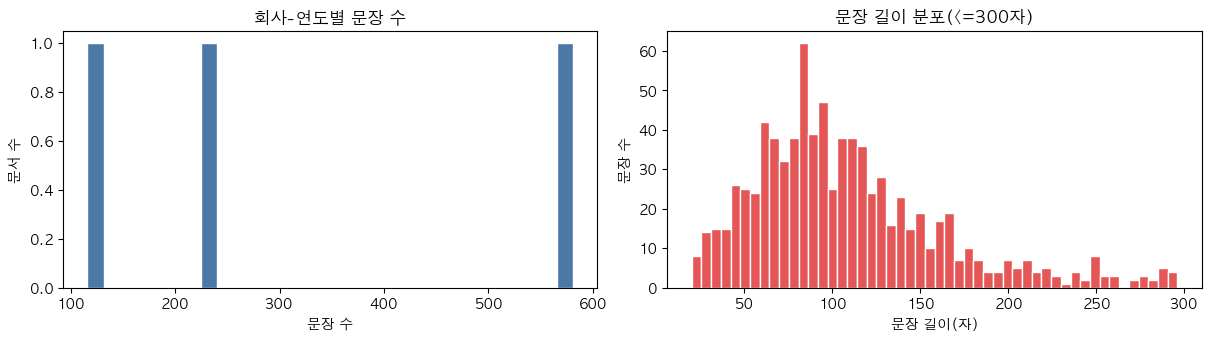

In [26]:
kiwi = Kiwi()
HANGUL_RE = re.compile(r'[가-힣]')


def split_sentences(text, return_dropped=False):
    kept, dropped = [], []
    for sent in kiwi.split_into_sents(text):
        s = sent.text.strip()
        if len(s) >= MIN_SENT_CHARS and HANGUL_RE.search(s):
            kept.append(s)
        elif s:
            dropped.append(s)
    return (kept, dropped) if return_dropped else kept


print(f'문장 분할 중... (회사-연도 {len(corpus_df)}개)')
corpus_df['sentences'] = corpus_df['core_text'].map(split_sentences)
corpus_df['n_sentences'] = corpus_df['sentences'].map(len)
assert (corpus_df['n_sentences'] > 0).all(), '문장이 0개인 행이 있습니다.'

print('▶ 회사-연도별 문장 수 요약:')
display(corpus_df['n_sentences'].describe().round(1))
print('총 문장 수:', int(corpus_df['n_sentences'].sum()))

# 문장 길이 분포 히스토그램
sent_lens = np.array([len(s) for sents in corpus_df['sentences'] for s in sents])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.3), constrained_layout=True)
axes[0].hist(corpus_df['n_sentences'], bins=30, color='#4C78A8', edgecolor='white')
axes[0].set_title('회사-연도별 문장 수'); axes[0].set_xlabel('문장 수'); axes[0].set_ylabel('문서 수')
axes[1].hist(sent_lens[sent_lens <= 300], bins=50, color='#E45756', edgecolor='white')
axes[1].set_title('문장 길이 분포(<=300자)'); axes[1].set_xlabel('문장 길이(자)'); axes[1].set_ylabel('문장 수')
plt.show()


In [27]:
# ▶ 문장 품질 점검: 살아남은 문장 / 버려진 문장 샘플
rng = np.random.default_rng(0)
flat = [s for sents in corpus_df['sentences'] for s in sents]
print('▶ 추출된 문장 무작위 12개 (임베딩에 실제 들어갈 문장):')
for s in rng.choice(np.array(flat, dtype=object), size=min(12, len(flat)), replace=False):
    print('  •', s[:120])

print('\n▶ 필터로 버려진 문장 예시:')
shown = 0
for _, row in corpus_df.iterrows():
    _, dropped = split_sentences(row['core_text'], return_dropped=True)
    for d in dropped[:4]:
        print('  ✗', repr(d[:80]))
        shown += 1
        if shown >= 12:
            break
    if shown >= 12:
        break


def inspect_company(key, n_sent=8):
    # 회사명(str) 또는 corpus_df 행 인덱스(int)로 raw->clean->문장을 한 번에 확인
    if isinstance(key, int):
        row = corpus_df.iloc[key]
    else:
        hit = corpus_df[corpus_df['company_name'] == key]
        row = hit.iloc[0] if len(hit) else corpus_df.iloc[0]
    print('=' * 80)
    print('회사:', row['company_name'], '| 사업연도:', row['fiscal_year'], '| 섹션:', row['present_core'],
          '| 문장수:', row['n_sentences'])
    print('--- core_raw (앞 300자) ---');  print(row['core_raw'][:300])
    print('--- core_text(앞 300자) ---');  print(row['core_text'][:300])
    print(f'--- 문장 {n_sent}개 ---')
    for s in row['sentences'][:n_sent]:
        print('  •', s[:120])


# 샘플의 각 회사-연도를 차례로 확인 (회사명으로 보고 싶으면 inspect_company('회사명'))
for i in range(len(corpus_df)):
    inspect_company(i)


▶ 추출된 문장 무작위 12개 (임베딩에 실제 들어갈 문장):
  • 주요 상품 및 서비스 상품명 또는 서비스명 (업무명) 주요내용 비고 대출 기업, 개인대출 - 예금 보통, 정기예금 - 전자금융 조회, 이체, 공과금 납부 온라인 전용 예금 지점 등 설치현황 
(기준일 : (단위 : 
  • 2018년도에 현지 완성차 업체를 통한 향후 기술동향 Trend를 파악하여 중장기적인 시장흐름에 대응 할 수 있을 것이라는 전략적인 판단과 향후 한국공장에 대한 추가 투자를 대체하고 친환경차 배터리로의 패러다임에 따
  • 소비자물가는 고금리 장기화에 따른 수요 위축, 외식물가 등 서비스물가 강세 완화, 석유류의 하락세로 상승폭이 둔화될 것으로 전망되나, 기상악화로 인한 과일·채소류 등 농축수산물 가격 상방 압력, 중동지역 등의 지정학
  • 부동산 산업 분야, 특히 부동산 개발 분야에서는 사업의 안정성 및 투명성 강화에 대한 요구가 지속적으로 확대되어 왔는데, 이로 인하여 부동산 개발과 관련한 자금 조달, 신용 관리, 사업 관리를 수행하는데 있어 신탁의
  • 국내외 시장여건 산업용지의 경우 산업구조가 고도화되면서 다양한 산업과 영역에서의 신제품을 포장하고 보관하기 위한 수요가 자연스럽게 증가하는 상황입니다.
  • 이사회 내에는 감사위원회, 사외이사후보추천위원회, 경영위원회, 내부거래위원회, 지속가능위원회 등 5개의 소위원회가 있습니다.
  • 다) 판매전략 지종 및 품질수준에 따른 차별가격 정책 도입과 동시에 물류기능 확보를 기반으로 한 적기공급 추진하고 있습니다.
  • 당사는 이자율 변동으로 인한 불확실성 제거와 금융비용 최소화를 위해 주기적인 금리동향 모니터링과 적절한 대응방안 수립을 운용하고 있습니다.
  • 회사명 2023년 9월 2022년 2021년 영업수익 점유율 영업수익 점유율 영업수익 점유율 우리자산신탁 % % % 전체 합계 % % % 영업수익 기준, 금융투자협회 시장에서 경쟁력을 좌우하는 요인 및 회사의 경쟁상
  • 우리은행 및 우리카드 주요 종속

## 7. E/S/G 기준문장 (차원당 3개 패러프레이즈)

각 차원 정의를 서로 다른 표현으로 쓴 **패러프레이즈 3개**. seed 사전 테마(탄소·에너지·폐기물 / 안전·노동·공급망 / 이사회·감사·주주)를 포괄한다. 여러 패러프레이즈의 cosine을 평균해 단일 문장 표현 민감도를 줄인다.

In [ ]:
reference_sentences = {
    'E': [
        '기업은 온실가스와 탄소 배출을 감축하고 탄소중립 및 재생에너지 전환 목표와 실행 계획을 추진한다.',
        '기업은 에너지와 전력 사용, 폐기물과 폐수를 관리하고 자원 재활용과 환경 리스크 대응 체계를 운영한다.',
        '기업은 환경경영 목표를 수립하고 환경 법규를 준수하며 기후변화 대응 성과를 체계적으로 관리한다.',
    ],
    'S': [
        '기업은 임직원의 산업안전과 보건을 보호하고 중대재해 예방을 위한 안전보건 관리체계를 운영한다.',
        '기업은 임직원의 노동권과 인권을 보호하고 교육훈련, 다양성, 고용안정을 확대한다.',
        '기업은 협력사와 공급망의 사회적 책임을 관리하고 지역사회와 이해관계자에 대한 책임을 이행한다.',
    ],
    'G': [
        '기업은 이사회와 사외이사의 독립성과 전문성을 강화하여 투명한 의사결정 체계를 구축한다.',
        '기업은 감사위원회와 내부통제를 통해 경영을 감시하고 윤리, 준법, 부패방지 체계를 운영한다.',
        '기업은 주주의 권리와 의결권을 보호하고 경영 정보를 투명하게 공개한다.',
    ],
}
for d, refs in reference_sentences.items():
    print(d, '패러프레이즈', len(refs), '개')


## 8. KURE-v1 임베딩 모델 로드

`nlpai-lab/KURE-v1`은 `BAAI/bge-m3`를 한국어 query-document 쌍으로 추가학습한 retrieval 임베딩(1024-dim, max seq 8192)이다. 기준문장↔문서 문장 비교에 적합하다. `normalize_embeddings=True`면 내적이 곧 cosine. 최초 실행 시 HF에서 모델(~2GB)을 자동 다운로드한다(Colab은 런타임마다 재다운로드).

In [ ]:
model = SentenceTransformer(MODEL_NAME, device=DEVICE)
try:                                          # 메서드명이 버전마다 다름(구/신)
    _dim = model.get_sentence_embedding_dimension()
except AttributeError:
    _dim = model.get_embedding_dimension()
print('로드 완료:', MODEL_NAME, '| dim:', _dim, '| device:', DEVICE)


## 9. 임베딩 계산 (무거운 셀 · 캐시)

기준문장과 코퍼스 전체 문장을 인코딩한다. 코퍼스 문장은 **중복 제거(`pd.factorize`)** 후 고유 문장만 계산해 시간을 줄이고, `06_dense_cosine_sentence_embeddings.npz`에 캐시한다. 문장 구성이 바뀌면 시그니처가 달라져 자동 재계산한다.

In [ ]:
def encode(texts, batch_size=EMBED_BATCH, progress=True):
    emb = model.encode([str(t) for t in texts], batch_size=batch_size,
                       normalize_embeddings=True, show_progress_bar=progress)
    return np.asarray(emb, dtype=np.float32)

ref_emb = {d: encode(refs, batch_size=16, progress=False) for d, refs in reference_sentences.items()}
print('기준문장 임베딩 shape (차원당):', {d: v.shape for d, v in ref_emb.items()})

# 문장 평탄화 + 문서별 슬라이스
all_sents, doc_slices, cursor = [], [], 0
for sents in corpus_df['sentences']:
    doc_slices.append((cursor, cursor + len(sents)))
    all_sents.extend(sents)
    cursor += len(sents)
all_sents = np.array(all_sents, dtype=object)
print('총 문장:', len(all_sents))

import hashlib
sig = hashlib.md5(('|'.join(map(str, corpus_df['n_sentences'])) + MODEL_NAME).encode()).hexdigest()[:10]

sent_emb = None
if OUTPUT_EMB_CACHE.exists():
    cache = np.load(OUTPUT_EMB_CACHE, allow_pickle=True)
    cached_sig = cache['sig'].item() if 'sig' in cache.files else None
    if cached_sig == sig and cache['emb'].shape[0] == len(all_sents):
        sent_emb = cache['emb']
        print('캐시 로드:', sent_emb.shape)

if sent_emb is None:
    codes, uniq = pd.factorize(all_sents)        # 가변길이 문자열에 안전한 중복 제거
    print(f'고유 문장 {len(uniq)} / 전체 {len(all_sents)} 인코딩 중...')
    uniq_emb = encode(list(uniq))
    sent_emb = uniq_emb[codes]
    np.savez_compressed(OUTPUT_EMB_CACHE, emb=sent_emb, sig=np.array(sig))
    print('캐시 저장:', OUTPUT_EMB_CACHE)

print('문장 임베딩 shape:', sent_emb.shape)


## 10. cosine 집계 — top-k 평균(주 피처) + max / docmean(비교용)

회사-연도별 (문장 × 패러프레이즈) cosine 행렬을 만들고 세 가지로 집계한다.

- **`cosine_{D}`** = 문장 축 상위 k(=10) 평균 → 패러프레이즈 평균 — **주 피처**. 해당 ESG 주제를 가장 강하게 다룬 구절들의 강도를 잡고, 분량(verbosity)에 둔감하다.
- `cosine_{D}_max` = 문장 축 최댓값 → 패러프레이즈 평균 — "그 주제 문장이 있는가". 단일 문장이라 노이즈 큼.
- `cosine_{D}_docmean` = 문서 평균벡터와 기준문장 cosine — 문서 전체 평균이라 비ESG 재무문장에 희석.

In [ ]:
def topk_mean(vals, k):
    if vals.size == 0:
        return np.nan
    k = min(k, vals.size)
    return float(np.sort(vals)[-k:].mean())


records = []
for (start, end) in doc_slices:
    doc_emb = sent_emb[start:end]
    rec = {}
    mean_vec = doc_emb.mean(axis=0)
    mean_vec = mean_vec / (np.linalg.norm(mean_vec) + 1e-12)
    for d in ESG_DIMS:
        sims = doc_emb @ ref_emb[d].T
        rec[f'cosine_{d}'] = float(np.mean([topk_mean(sims[:, j], TOPK) for j in range(sims.shape[1])]))
        rec[f'cosine_{d}_max'] = float(sims.max(axis=0).mean())
        rec[f'cosine_{d}_docmean'] = float((mean_vec @ ref_emb[d].T).mean())
    records.append(rec)

cos_df = pd.DataFrame.from_records(records)
print('▶ cosine 피처 요약:')
display(cos_df.describe().round(4))


## 11. 피처 테이블 조립 및 분포 확인

In [ ]:
features = pd.concat([
    corpus_df[['company_name', 'stock_code', 'fiscal_year', 'esg_year',
               'industry', 'n_sentences', 'core_len_chars']].reset_index(drop=True),
    cos_df.reset_index(drop=True),
], axis=1)

assert len(features) == len(corpus_df), 'features 행 수 불일치'
assert features[STRICT_KEY_COLS].notna().all().all(), 'features 키 결측'
assert features.duplicated(KEY_COLS).sum() == 0, 'features PK 중복'
assert features[COSINE_COLS].notna().all().all(), 'cosine 주 피처에 결측'

display(features.head())
display(features[COSINE_COLS].describe())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, col in zip(axes, COSINE_COLS):
    ax.hist(features[col], bins=30, color='#4C78A8', edgecolor='white')
    ax.set_title(col); ax.set_xlabel('cosine (top-k 평균)'); ax.set_ylabel('문서 수')
plt.show()


## 12. ESG 등급 데이터 준비 및 merge

등급을 `S=6 … D=0`으로 숫자화하고 `stock_code+fiscal_year+esg_year`로 검증 merge(05b와 동일).

In [ ]:
grades = master[['company_name', 'stock_code', 'fiscal_year', 'esg_year',
                 'esg_grade', 'e_grade', 's_grade', 'g_grade']].copy()
grades = grades.sort_values(KEY_COLS).reset_index(drop=True)
for col in ['esg_grade', 'e_grade', 's_grade', 'g_grade']:
    grades[col] = grades[col].astype(str).str.strip()
grades['esg_grade_num'] = grades['esg_grade'].map(GRADE_MAP)
grades['e_grade_num'] = grades['e_grade'].map(GRADE_MAP)
grades['s_grade_num'] = grades['s_grade'].map(GRADE_MAP)
grades['g_grade_num'] = grades['g_grade'].map(GRADE_MAP)
grades['high_esg'] = (grades['esg_grade_num'] >= HIGH_ESG_CUTOFF).astype(int)

assert grades.duplicated(STRICT_KEY_COLS).sum() == 0, 'grades strict key 중복'
assert grades[['esg_grade_num'] + GRADE_NUM_COLS].notna().all().all(), '숫자화 실패 등급 존재'

merged = features.merge(
    grades[STRICT_KEY_COLS + ['esg_grade', 'e_grade', 's_grade', 'g_grade',
                              'esg_grade_num', 'high_esg'] + GRADE_NUM_COLS],
    on=STRICT_KEY_COLS, how='left', validate='one_to_one', indicator=True)
assert (merged['_merge'] == 'both').all(), '등급 merge 누락 행 존재'
merged = merged.drop(columns=['_merge'])

print('등급 매칭률 100% | high_esg(A 이상=1) 분포:')
print(merged['high_esg'].value_counts().sort_index().to_string())
display(merged[['company_name', 'fiscal_year'] + COSINE_COLS + ['esg_grade_num', 'high_esg'] + GRADE_NUM_COLS].head())


## 13. Spearman 3×3 교차표 (cosine × E/S/G 등급)

`cosine_E/S/G`와 `e/s/g_grade_num`의 모든 조합에 대해 Spearman 순위상관·p-value. **대각선이 강하고 비대각선이 약하면** 차원별 의미 측정이 성공한 패턴.

In [ ]:
rho_matrix = pd.DataFrame(index=COSINE_COLS, columns=GRADE_NUM_COLS, dtype=float)
pval_matrix = pd.DataFrame(index=COSINE_COLS, columns=GRADE_NUM_COLS, dtype=float)

sp = merged.dropna(subset=COSINE_COLS + GRADE_NUM_COLS)
for tc in COSINE_COLS:
    for gc in GRADE_NUM_COLS:
        pair = sp[[tc, gc]].dropna()
        if pair[tc].nunique() < 2 or pair[gc].nunique() < 2:
            rho, pval = np.nan, np.nan
        else:
            rho, pval = spearmanr(pair[tc], pair[gc])
        rho_matrix.loc[tc, gc] = rho
        pval_matrix.loc[tc, gc] = pval

print('Spearman rho matrix'); display(rho_matrix.round(3))
print('p-value matrix'); display(pval_matrix)


## 14. Spearman 교차표 heatmap

In [ ]:
def pvalue_stars(p):
    if pd.isna(p):
        return ''
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''


annot = rho_matrix.copy().astype(object)
for r in rho_matrix.index:
    for c in rho_matrix.columns:
        rho = rho_matrix.loc[r, c]
        annot.loc[r, c] = 'NA' if pd.isna(rho) else f'{rho:.2f}{pvalue_stars(pval_matrix.loc[r, c])}'

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
sns.heatmap(rho_matrix.astype(float), annot=annot, fmt='', center=0, cmap='RdBu_r',
            vmin=-1, vmax=1, linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Spearman rho'}, ax=ax)
ax.set_title('Dense cosine x ESG grade Spearman rho')
ax.set_xlabel('ESG grade'); ax.set_ylabel('Dense cosine feature')
ax.set_xticklabels(['E grade', 'S grade', 'G grade'])
ax.set_yticklabels(['E text', 'S text', 'G text'], rotation=0)
fig.savefig(OUTPUT_HEATMAP, dpi=200, bbox_inches='tight')
plt.show()
print('heatmap 저장:', OUTPUT_HEATMAP)


## 15. 집계 변형 비교 (top-k vs max vs docmean)

세 집계가 등급과 얼마나 연관되는지 비교한다. `rho_own_grade`는 같은 차원 등급(예: cosine_E↔e_grade), `rho_esg_grade`는 통합 등급. pooling별 평균 |rho|로 주 피처(top-k) 선택을 정당화한다.

In [ ]:
variants = {'topk': '', 'max': '_max', 'docmean': '_docmean'}
rows = []
for vname, suf in variants.items():
    for d in ESG_DIMS:
        col = f'cosine_{d}{suf}'
        own = f'{d.lower()}_grade_num'
        r_own, p_own = spearmanr(merged[col], merged[own])
        r_int, p_int = spearmanr(merged[col], merged[INTEGRATED_GRADE_NUM_COL])
        rows.append({'pooling': vname, 'dim': d, 'feature': col,
                     'rho_own_grade': r_own, 'p_own': p_own,
                     'rho_esg_grade': r_int, 'p_esg': p_int})
pooling_cmp = pd.DataFrame(rows)
display(pooling_cmp.round(4))

print('▶ pooling별 평균 |상관| (클수록 신호 강함):')
display(pooling_cmp.assign(abs_own=pooling_cmp['rho_own_grade'].abs(),
                           abs_esg=pooling_cmp['rho_esg_grade'].abs())
        .groupby('pooling')[['abs_own', 'abs_esg']].mean().round(4))


## 16. 수렴타당도 — Dense cosine × Seed TF-IDF

05b의 `tfidf_E/S/G`(빈도)와 본 노트북의 `cosine_E/S/G`(의미)는 **독립적으로 만든 두 텍스트 측정**이다. 같은 차원끼리(대각선) 양(+) Spearman이면 두 측정이 같은 신호를 잡는다는 **수렴타당도** 근거(의미 vs 어휘빈도라 완전 일치는 아님).

In [ ]:
if TFIDF_FEATURES.exists():
    tfidf = pd.read_parquet(TFIDF_FEATURES)
    tf_cols = ['tfidf_E', 'tfidf_S', 'tfidf_G']
    left = merged.copy()
    left['stock_code'] = left['stock_code'].astype(str).str.zfill(6)
    tfidf['stock_code'] = tfidf['stock_code'].astype(str).str.zfill(6)
    tfidf['fiscal_year'] = tfidf['fiscal_year'].astype(int)
    tfidf['esg_year'] = tfidf['esg_year'].astype(int)
    conv = left.merge(tfidf[STRICT_KEY_COLS + tf_cols], on=STRICT_KEY_COLS, how='inner', validate='one_to_one')
    print('수렴타당도 표본 수:', len(conv))

    conv_rho = pd.DataFrame(index=COSINE_COLS, columns=tf_cols, dtype=float)
    conv_p = pd.DataFrame(index=COSINE_COLS, columns=tf_cols, dtype=float)
    for cc in COSINE_COLS:
        for tt in tf_cols:
            r, p = spearmanr(conv[cc], conv[tt])
            conv_rho.loc[cc, tt] = r
            conv_p.loc[cc, tt] = p
    print('Dense cosine x TF-IDF Spearman rho'); display(conv_rho.round(3))

    annot2 = conv_rho.copy().astype(object)
    for r in conv_rho.index:
        for c in conv_rho.columns:
            annot2.loc[r, c] = f'{conv_rho.loc[r, c]:.2f}{pvalue_stars(conv_p.loc[r, c])}'
    fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)
    sns.heatmap(conv_rho.astype(float), annot=annot2, fmt='', center=0, cmap='PuOr_r',
                vmin=-1, vmax=1, linewidths=0.5, linecolor='white',
                cbar_kws={'label': 'Spearman rho'}, ax=ax)
    ax.set_title('수렴타당도: Dense cosine x Seed TF-IDF')
    ax.set_xlabel('Seed TF-IDF'); ax.set_ylabel('Dense cosine')
    ax.set_xticklabels(['E tfidf', 'S tfidf', 'G tfidf'])
    ax.set_yticklabels(['E cos', 'S cos', 'G cos'], rotation=0)
    fig.savefig(OUTPUT_CONVERGENT_HEATMAP, dpi=200, bbox_inches='tight')
    plt.show()
    conv_rho.to_csv(OUTPUT_CONVERGENT, encoding='utf-8-sig')
    print('대각선(같은 차원) 수렴 상관:',
          {d: round(float(conv_rho.loc[f'cosine_{d}', f'tfidf_{d}']), 3) for d in ESG_DIMS})
    print('저장:', OUTPUT_CONVERGENT, '|', OUTPUT_CONVERGENT_HEATMAP)
else:
    conv_rho = None
    print('05 TF-IDF 피처가 없어 수렴타당도를 건너뜁니다. 05b 노트북을 먼저 실행하세요.')


## 17. ESG 우수/비우수 그룹 평균 차이 검정

가이드(03) 권장 보완 검정. A 이상(`high_esg=1`) vs 그 외에서 cosine 피처 평균이 다른지 Mann-Whitney U와 Welch t-test로 확인한다.

In [ ]:
hi = merged[merged['high_esg'] == 1]
lo = merged[merged['high_esg'] == 0]
gd_rows = []
for col in COSINE_COLS:
    u, pu = mannwhitneyu(hi[col], lo[col], alternative='two-sided')
    t, pt = ttest_ind(hi[col], lo[col], equal_var=False)
    gd_rows.append({'feature': col,
                    'mean_high(A+)': hi[col].mean(), 'mean_low': lo[col].mean(),
                    'mean_diff': hi[col].mean() - lo[col].mean(),
                    'mannwhitney_p': pu, 'welch_t': t, 'welch_p': pt})
group_diff = pd.DataFrame(gd_rows)
display(group_diff.round(4))
group_diff.to_csv(OUTPUT_GROUPDIFF, index=False, encoding='utf-8-sig')
print('저장:', OUTPUT_GROUPDIFF)


## 18. 회귀 패널 구성

통합 ESG 등급(`esg_grade_num`)을 종속변수로, `cosine_E/S/G`를 설명변수로 둔다. Binary Logit은 A 이상(`>=4`)을 우수로 본다. 길이 통제용 `report_len`(문장 수 표준화)을 추가한다 — 분량(cheap-talk)을 통제해도 cosine이 유의하면 단순 verbosity 이상의 신호라는 근거.

In [ ]:
merged['report_len'] = (merged['n_sentences'] - merged['n_sentences'].mean()) / merged['n_sentences'].std()

REGRESSION_FEATURES_A = COSINE_COLS                  # Spec A: 05b와 동일 (cosine만)
REGRESSION_FEATURES_B = COSINE_COLS + ['report_len']  # Spec B: + 보고서 길이 통제

panel = merged.dropna(subset=[INTEGRATED_GRADE_NUM_COL, 'high_esg'] + REGRESSION_FEATURES_B).copy()
assert len(panel) > 0
assert set(panel['high_esg'].unique()) == {0, 1}, 'Binary Logit을 위해 high_esg는 0/1 모두 필요'

print('회귀 패널 shape:', panel.shape)
print('통합 ESG 등급 분포:'); print(panel['esg_grade'].value_counts().sort_index().to_string())
print('\nhigh_esg 분포:'); print(panel['high_esg'].value_counts().sort_index().to_string())
display(panel[['company_name', 'esg_grade', 'esg_grade_num', 'high_esg'] + REGRESSION_FEATURES_B].head())


## 19. 회귀분석 — 두 스펙 × 세 모형

- **Spec A (05b 동일)**: `cosine_E/S/G`만.
- **Spec B (+길이 통제)**: `cosine_E/S/G + report_len`.

각 스펙에서 OLS(HC3 robust) · Binary Logit · Ordered Logit. OLS=연속 baseline, Binary Logit=A 이상 여부(odds ratio), Ordered Logit=등급 서열 보존.

In [ ]:
def run_models(panel_df, feats, spec):
    out = []
    Xo = sm.add_constant(panel_df[feats], has_constant='add')
    ols = sm.OLS(panel_df[INTEGRATED_GRADE_NUM_COL], Xo).fit(cov_type='HC3')
    t = pd.DataFrame({'term': ols.params.index, 'coef': ols.params.values,
                      'std_err': ols.bse.values, 'p_value': ols.pvalues.values})
    t['odds_ratio'] = np.nan
    t['model'], t['metric_name'], t['metric_value'], t['spec'] = 'OLS', 'r_squared', ols.rsquared, spec
    out.append(t)

    Xb = sm.add_constant(panel_df[feats], has_constant='add')
    bl = sm.Logit(panel_df['high_esg'], Xb).fit(disp=False)
    tb = pd.DataFrame({'term': bl.params.index, 'coef': bl.params.values,
                       'std_err': bl.bse.values, 'p_value': bl.pvalues.values})
    tb['odds_ratio'] = np.exp(tb['coef'])
    tb['model'], tb['metric_name'], tb['metric_value'], tb['spec'] = 'Binary Logit', 'pseudo_r_squared', bl.prsquared, spec
    out.append(tb)

    om = OrderedModel(panel_df[INTEGRATED_GRADE_NUM_COL], panel_df[feats], distr='logit').fit(method='bfgs', disp=False)
    to = pd.DataFrame({'term': om.params.index, 'coef': om.params.values,
                       'std_err': om.bse.values, 'p_value': om.pvalues.values})
    to = to[to['term'].isin(feats)].copy()
    to['odds_ratio'] = np.nan
    to['model'], to['metric_name'], to['metric_value'], to['spec'] = 'Ordered Logit', 'aic', om.aic, spec
    out.append(to)
    return pd.concat(out, ignore_index=True), (ols, bl, om)


tblA, modA = run_models(panel, REGRESSION_FEATURES_A, 'A_cosine_only')
print('=' * 70, '\nSPEC A (05b 동일: cosine_E/S/G)\n', '=' * 70)
print(modA[0].summary()); print(modA[1].summary()); print(modA[2].summary())

tblB, modB = run_models(panel, REGRESSION_FEATURES_B, 'B_plus_length')
print('=' * 70, '\nSPEC B (+ report_len 길이 통제)\n', '=' * 70)
print(modB[0].summary()); print(modB[1].summary()); print(modB[2].summary())

regression_summary = pd.concat([tblA, tblB], ignore_index=True)[
    ['spec', 'model', 'term', 'coef', 'std_err', 'p_value', 'odds_ratio', 'metric_name', 'metric_value']]
display(regression_summary)


## 20. 산출물 저장

피처(parquet), Spearman 교차표, 집계 비교, 수렴타당도, 그룹차, 회귀 요약(CSV + 모형별 txt). heatmap PNG는 앞에서 저장. Colab이면 Drive(`data/processed`, `reports/figures`)에 그대로 기록된다.

In [ ]:
features.to_parquet(OUTPUT_FEATURES, index=False)
rho_matrix.to_csv(OUTPUT_RHO, encoding='utf-8-sig')
pval_matrix.to_csv(OUTPUT_PVAL, encoding='utf-8-sig')
pooling_cmp.to_csv(OUTPUT_POOLING, index=False, encoding='utf-8-sig')
regression_summary.to_csv(OUTPUT_REGRESSION_SUMMARY, index=False, encoding='utf-8-sig')

OUTPUT_OLS_SUMMARY.write_text(
    'SPEC A (cosine only)\n' + modA[0].summary().as_text() +
    '\n\nSPEC B (+ report_len)\n' + modB[0].summary().as_text(), encoding='utf-8')
OUTPUT_BINARY_LOGIT_SUMMARY.write_text(
    'SPEC A (cosine only)\n' + modA[1].summary().as_text() +
    '\n\nSPEC B (+ report_len)\n' + modB[1].summary().as_text(), encoding='utf-8')
OUTPUT_ORDERED_LOGIT_SUMMARY.write_text(
    'SPEC A (cosine only)\n' + modA[2].summary().as_text() +
    '\n\nSPEC B (+ report_len)\n' + modB[2].summary().as_text(), encoding='utf-8')

required = [OUTPUT_FEATURES, OUTPUT_RHO, OUTPUT_PVAL, OUTPUT_POOLING,
            OUTPUT_REGRESSION_SUMMARY, OUTPUT_OLS_SUMMARY, OUTPUT_BINARY_LOGIT_SUMMARY,
            OUTPUT_ORDERED_LOGIT_SUMMARY, OUTPUT_GROUPDIFF, OUTPUT_HEATMAP]
for p in required:
    assert p.exists(), f'저장 실패: {p}'
    print('저장 완료:', p)
print('\nfeatures shape:', features.shape)
display(features.head())


## 21. 결과 정리 — Dense 기준문장 cosine

### 이 노트북의 위치
05b의 seed TF-IDF(빈도)와 평행하게 **의미 기반(dense)** E/S/G 측정을 만들어 같은 검증(Spearman 3×3 → OLS·Binary·Ordered Logit)을 적용했다.

### 읽는 법
- **Spearman 3×3 (13·14)**: 대각선(E text↔E grade 등)이 비대각선보다 강하면 차원별 의미 측정이 작동한 것. 양(+)이면 ESG 서술이 강한 기업-연도일수록 해당 등급이 높은 경향.
- **집계 비교 (15)**: top-k 평균이 max·docmean보다 안정적/강하면 주 피처 선택이 정당화된다.
- **수렴타당도 (16)**: cosine과 TF-IDF의 대각선 상관이 양(+)이면 서로 다른 두 텍스트 측정이 같은 신호를 잡는다는 근거.
- **회귀 (19)**: Spec B에서 `report_len`(분량)을 통제한 뒤에도 cosine 계수가 유의하면, 단순 공시 분량(cheap-talk)을 넘는 ESG 신호로 해석할 여지가 커진다.

### 전처리 점검 포인트 (4~6)
- 4번: II/IV/VI 커버리지와 섹션별 길이 → 모든 기업-연도가 핵심 섹션을 가졌는지.
- 5번: 클리닝 전후 문자 감소율·지저분한 예시 before/after → 너무 많이 지우지 않았는지.
- 6번: 문장 수/길이 분포 + 살아남은/버려진 문장 샘플 + `inspect_company('회사명')` → 문장 분할 품질 직접 확인. 결과가 이상하면 `MIN_SENT_CHARS`나 5번 클리닝 규칙을 조정한다.

### 한계
- **cheap-talk**: 공시 표현 ≠ 실제 ESG 성과.
- **표본**: 381 기업-연도 pilot, 무작위 표본 아님.
- **연관 ≠ 인과**: "이 표본에서는 ESG 서술이 강할수록 등급이 높은 경향이 있었다" 정도로 읽는다.
- **모델 의존성**: KURE-v1 사전학습 분포에 결과가 영향받음 → 알파 분석으로 bge-m3 등과의 강건성 비교 가능.
